In [6]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

nltk.download('stopwords', quiet=True)

# 퀄컴 특허 데이터 로드 및 분석용 데이터프레임 구성
raw_df = pd.read_csv('Qualcomm_patents_2020-2024.csv')

patent_df = pd.DataFrame({
    'display_key': raw_df['Display Key'],
    'title': raw_df['Title'].fillna(''),
    'document': raw_df['Title'].fillna('') + ' ' + raw_df['Abstract'].fillna(''),
    'label': pd.to_datetime(raw_df['Application Date'], errors='coerce').dt.year.astype(str)
})

print('전체 문서 수:', len(patent_df), '| 연도 구간 수:', patent_df['label'].nunique())

전체 문서 수: 5073 | 연도 구간 수: 5


In [7]:
dup = raw_df[raw_df['Application Number'].duplicated(keep=False)].sort_values(['Application Number', 'Kind'])

# 출원번호별로 A1과 B2를 한 줄로 합쳐서 비교
a = dup[dup['Kind'] == 'A1'].set_index('Application Number')
b = dup[dup['Kind'] == 'B2'].set_index('Application Number')
common = a.index.intersection(b.index)

cmp = pd.DataFrame({
    'A1 번호': a.loc[common, 'Display Key'],
    'B2 번호': b.loc[common, 'Display Key'],
    '출원일 동일': a.loc[common, 'Application Date'] == b.loc[common, 'Application Date'],
    '제목 동일': a.loc[common, 'Title'].str.lower() == b.loc[common, 'Title'].str.lower(),
    '요약 동일': a.loc[common, 'Abstract'] == b.loc[common, 'Abstract'],
    '우선일 동일': a.loc[common, 'Earliest Priority Date'] == b.loc[common, 'Earliest Priority Date'],
})
print(f'비교한 쌍: {len(cmp)}개')
print(cmp[['출원일 동일', '제목 동일', '요약 동일', '우선일 동일']].sum())
display(cmp.head(10))

비교한 쌍: 29개
출원일 동일    29
제목 동일     28
요약 동일     29
우선일 동일     0
dtype: int64


,A1 번호,B2 번호,출원일 동일,제목 동일,요약 동일,우선일 동일
Application Number,,,,,,
"17/446,805",US 2022/0070890 A1,US 12786985 B2,True,True,True,False
"17/674,756",US 2023/0262716 A1,US 12787014 B2,True,True,True,False
"17/712,061",US 2023/0318797 A1,US 12785915 B2,True,True,True,False
"18/003,465",US 2023/0254022 A1,US 12785771 B2,True,True,True,False
"18/178,281",US 2024/0298143 A1,US 12786667 B2,True,True,True,False
"18/182,816",US 2024/0313844 A1,US 12785779 B2,True,True,True,False
"18/251,360",US 2024/0032076 A1,US 12787040 B2,True,True,True,False
"18/256,043",US 2024/0106565 A1,US 12785843 B2,True,False,True,False
"18/264,224",US 2024/0048348 A1,US 12785914 B2,True,True,True,False


In [8]:
# 1) 출원번호 기준 중복 확인
dup_app = raw_df['Application Number'].duplicated(keep=False)
print(f'출원번호가 같은 문서: {dup_app.sum()}건 ({raw_df.loc[dup_app, "Application Number"].nunique()}개 출원)')
print(raw_df.loc[dup_app].groupby('Application Number')['Kind']
      .agg(lambda s: '+'.join(sorted(s))).value_counts())

# 2) 같은 출원이면 등록본(B)을 우선 남기고 나머지 제거
is_b = raw_df['Kind'].str.startswith('B')
keep_idx = (raw_df.assign(_b=is_b).sort_values('_b', ascending=False)
            .drop_duplicates(subset='Application Number', keep='first').index)
mask = raw_df.index.isin(keep_idx)

n_before = len(raw_df)
raw_df = raw_df.loc[mask].reset_index(drop=True)
patent_df = patent_df.loc[mask].reset_index(drop=True)   # 두 데이터프레임의 행 순서를 맞춤
print(f'\n중복 제거: {n_before}건 → {len(patent_df)}건 ({n_before - len(patent_df)}건 제거)')

# 3) 데이터 범위 확인 (3장, 6장 해석용)
print('\n[관할]'); print(raw_df['Jurisdiction'].value_counts())
print('\n[출원일 범위]', raw_df['Application Date'].min(), '~', raw_df['Application Date'].max())
print('[공개일 범위]', raw_df['Publication Date'].min(), '~', raw_df['Publication Date'].max())
print('\n[출원인 상위]'); print(raw_df['Applicants'].value_counts().head(8))

출원번호가 같은 문서: 58건 (29개 출원)
Kind
A1+B2    29
Name: count, dtype: int64

중복 제거: 5073건 → 5044건 (29건 제거)

[관할]
Jurisdiction
US    5044
Name: count, dtype: int64

[출원일 범위] 2020-01-03 ~ 2024-12-23
[공개일 범위] 2020-05-14 ~ 2026-11-05

[출원인 상위]
Applicants
QUALCOMM INC                                                                     4958
QUALCOMM Incorporated                                                              38
QUALCOMM INC;;QUALCOMM INCORPROATED                                                19
QUALCOMM INCORPORATED                                                              16
CHEN SIYI;;XU CHANGLONG;;SUN JING;;ZHANG XIAOXIA;;PRAKASH RAJAT;;QUALCOMM INC       1
QUALCOMM INC;;QUALCOMM INCORPORTATED                                                1
QUALCOMM LNCORPORATED                                                               1
LI CHUNXIA;;SUN WEI;;CHEN FENG;;QUALCOMM INC                                        1
Name: count, dtype: int64


In [30]:
stop_words = set(stopwords.words('english'))

# 특허 명세서 상투어 및 통신 공통 불용어 추가
stop_words.update([
   "control","channel", "may", "first", "second", "one", "two", "third",
    "also", "another", "each", "every",
    "within", "without", "thereof", "therein",
    "thereby", "wherein", "herein", "hereby",
    "aspects", "aspect", "disclosure",
    "embodiment", "embodiments", "described",
    "description", "invention", "present",
    "example", "examples", "plurality",
    "comprising", "comprise", "comprises",
    "include", "includes", "including",
    "provide", "provides", "provided",
    "using", "based", "associated",
    "configured", "configuration", "configurations",
    "determine", "determining", "determined", "determination",
    "method", "methods", "system", "systems",
    "device", "devices", "apparatus",
    "equipment", "entity", "entities",
    "information", "data", "user", "ue", "ues",
    "can", "would", "could", "said", "such",
    "various", "particular", "least",
    "more", "less", "same", "other",
    "communication", "communications", "communicate", "communicating",
    "transmit", "transmits", "transmitting", "transmitted",
    "transmission", "transmissions",
    "receive", "receives", "receiving", "received",
    "message", "messages",
    "set", "sets", "group", "groups",
    "subset", "subsets", "portion",
    "via", "according", "corresponding",
    "respective", "multiple", "instance",
    "generally", "indication", "indications",
    "indicating", "indicate", "indicated", "indicates",
    "reference", "part", "parts",
    "base", "station", "node",
    "signal", "signals", "signaling",
    "numerous", "certain", "relate", "relates", "related", "relating",
    "accordance", "technique", "techniques",
    "perform", "performs", "performed", "performing",
    "use", "uses", "used",
    "whether", "disclosed", "different", "selected", "select",
    "obtain", "obtained", "obtaining",
    "generate", "generates", "generated", "generating",
    "support", "supports", "supported", "supporting",
    "identify", "identifies", "identified", "identifying",
    "monitor", "monitors", "monitored", "monitoring",
    "trigger", "triggered", "triggering",
    "enable", "enables", "enabled", "enabling",
    "wireless", "network", "networks",
    "resource", "resources",
    "parameter", "parameters",
    "value", "values",
    "time", "slot", "slots",
    "state", "states",
    "mode", "modes",
    "type", "types",
    "number", "quantity",
    "operation", "operations",
    "procedure", "procedures",
    "condition", "conditions", "case",
    "occasion", "occasions",
    "capability", "capabilities",
    "location", "target", "candidate", "available", "single"
])

keep_short_terms = {'bwp','csi','dci','ack','cqi','rrc','mac','phy','qos','lte','v2x','5g','6g','ntn','iab','ris','ai','ml','xr','iot','tci','ssb','srs','prs','sps','tdd','fdd','sci','uci','nru','lbt','rlc','pci','pmi','mbs'}

def preprocess(text):
    text = re.sub(r'[^a-zA-Z0-9]', ' ', str(text)).lower()
    words = [w for w in text.split() if not w.isdigit() and (len(w) > 3 or w in keep_short_terms)]
    return ' '.join(w for w in words if w not in stop_words)                           # 4. 불용어 제거

patent_df['clean_doc'] = patent_df['document'].apply(preprocess)
print('전체 전처리 완료:', len(patent_df), '건')

전체 전처리 완료: 5044 건


In [31]:
vectorizer = TfidfVectorizer(stop_words='english',   # sklearn 불용어 추가 필터링
                             max_features=1000,      # 상위 1,000개 단어
                             max_df=0.5)             # 50% 넘는 문서에 나오는 단어 제외

X = vectorizer.fit_transform(patent_df['clean_doc']) # 희소행렬
terms = vectorizer.get_feature_names_out()           # 열 번호 → 단어

print('TF-IDF 행렬 크기:', X.shape)
print(f'0이 아닌 원소 비율: {X.nnz / np.prod(X.shape):.2%}')

TF-IDF 행렬 크기: (5044, 1000)
0이 아닌 원소 비율: 1.33%


토픽-단어 행렬 V_k^T 크기: (20, 1000)


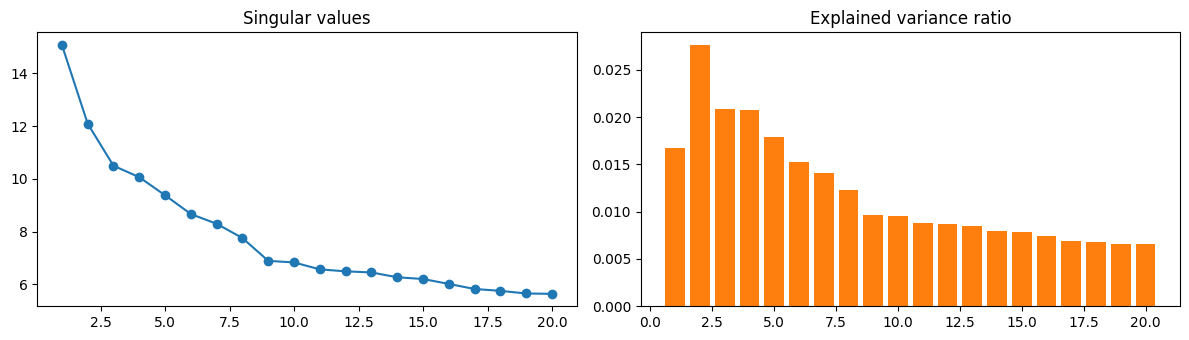

20개 토픽 누적 설명분산: 24.1%


In [32]:
n_topics = 20
svd_model = TruncatedSVD(n_components=n_topics, algorithm='randomized', n_iter=100, random_state=122)
svd_model.fit(X)

print('토픽-단어 행렬 V_k^T 크기:', svd_model.components_.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(range(1, n_topics + 1), svd_model.singular_values_, 'o-')
axes[0].set_title('Singular values')
axes[1].bar(range(1, n_topics + 1), svd_model.explained_variance_ratio_, color='tab:orange')
axes[1].set_title('Explained variance ratio')
plt.tight_layout()
plt.show()

print(f'{n_topics}개 토픽 누적 설명분산: {svd_model.explained_variance_ratio_.sum():.1%}')

In [33]:
def topic_table(components, words, n=6, show_negative=False):
    table = {}
    for t, weight in enumerate(components):
        order = weight.argsort()                                   # 오름차순 인덱스
        row = {'(+) 상위 단어': ', '.join(words[order[::-1][:n]])}
        if show_negative:
            row['(−) 하위 단어'] = ', '.join(words[order[:n]])
        table[f'T{t+1}'] = row
    return pd.DataFrame(table).T

display(topic_table(svd_model.components_, terms, show_negative=True))

doc_topic_lsa = svd_model.transform(X)          # (전체 문서 수 x 20)
print('문서-토픽 행렬 크기:', doc_topic_lsa.shape)

,(+) 상위 단어,(−) 하위 단어
T1,"sidelink, feedback, csi, beam, uplink, report","constellation, shaping, amplifier, lens, bluetooth, dictionary"
T2,"csi, report, beam, uplink, reporting, downlink","sidelink, sci, pool, reservation, positioning, coordination"
T3,"csi, sidelink, report, reporting, reports, measurement","uplink, random, beam, access, cell, harq"
T4,"beam, failure, beams, recovery, cell, access","feedback, harq, automatic, repeat, hybrid, ack"
T5,"beam, harq, feedback, failure, recovery, beams","random, access, prach, rach, uplink, preamble"
T6,"random, access, feedback, harq, prach, beam","uplink, cell, bwp, grant, handover, bandwidth"
T7,"cell, handover, harq, feedback, source, cells","uplink, grant, beam, downlink, pusch, scheduling"
T8,"bwp, bandwidth, frequency, band, active, switching","uplink, cell, handover, timing, grant, advance"
T9,"positioning, sps, prs, scheduling, semi, persistent","feedback, carrier, uplink, frequency, band, aggregation"
T10,"positioning, prs, uplink, harq, timing, advance","sps, scheduling, semi, persistent, downlink, dci"


문서-토픽 행렬 크기: (5044, 20)


In [34]:
doc_lsa_norm = normalize(doc_topic_lsa)          # 문서 좌표를 길이 1로 정규화 (내적 = 코사인 유사도)

def search(query, top_n=5):
    q_tfidf = vectorizer.transform([query])          # 1. 검색어 → TF-IDF 벡터
    q_hat = svd_model.transform(q_tfidf)             # 2. TF-IDF → 토픽 좌표 (q V_k)
    score = doc_lsa_norm @ normalize(q_hat).ravel()  # 3. 모든 문서와 코사인 유사도 계산
    top = np.argsort(score)[::-1][:top_n]            # 상위 top_n개 추출
    return pd.DataFrame({
        '유사도': score[top].round(3),
        '출원연도': patent_df.label[top].values,
        '특허번호': patent_df.display_key[top].values,
        '발명의명칭': patent_df.title[top].values
    })

display(search('sidelink resource pool'))

# 단어 간 잠재 의미 유사도 계산
term_vec = normalize(svd_model.components_.T * svd_model.singular_values_)   # (단어 수 x 20)
word2idx = {w: i for i, w in enumerate(terms)}

def similar_words(word, top_n=6):
    if word not in word2idx:
        return "사전에 없는 단어"
    sims = term_vec @ term_vec[word2idx[word]]
    top = np.argsort(sims)[::-1][1:top_n + 1]          # 자기 자신 제외
    return ', '.join(terms[top])

display(pd.DataFrame({'비슷한 단어': {w: similar_words(w) for w in ['sidelink', 'beam', 'harq', 'wlan']}}))

,유사도,출원연도,특허번호,발명의명칭
0,1.000,2023,US 2024/0292433 A1,TRANSMIT PARAMETER FOR PORTION OF SIDELINK RESOURCE POOL
1,0.999,2023,US 2025/0056583 A1,RADAR TRANSMISSIONS USING RESOURCES OF SIDELINK RESOURCE SUB-POOLS
2,0.999,2020,US 11457455 B2,Signaling for selecting a subset of sidelink transmit resource pool by a receiver UE in sidelink
3,0.998,2020,US 11838909 B2,Sidelink resource pool for control signaling
4,0.997,2021,US 2024/0284335 A1,WAKEUP SIGNAL (WUS) RESOURCE CONFIGURATION FOR SIDELINK WIRELESS COMMUNICATIONS


,비슷한 단어
sidelink,"preemption, mini, pool, subchannel, subchannels, reservations"
beam,"pair, sweeping, management, pairs, beams, sweep"
harq,"repeat, hybrid, automatic, ack, processes, process"
wlan,"local, area, cellular, peripheral, bluetooth, radio"


In [35]:
!pip install -q rank_bm25

from rank_bm25 import BM25Okapi

# 1. 전처리된 전체 문서 토큰화 및 BM25 인덱스 생성
tokenized_corpus = [doc.split() for doc in patent_df['clean_doc']]
bm25 = BM25Okapi(tokenized_corpus)

# 2. BM25 기반 대표 특허 검색 함수 (기존 LSI search 함수와 동일한 출력 양식)
def search_bm25(query, top_n=5):
    tokenized_query = preprocess(query).split()              # 검색어도 동일한 전처리 적용
    scores = bm25.get_scores(tokenized_query)                # 전체 문서별 BM25 점수 계산
    top = np.argsort(scores)[::-1][:top_n]                   # 점수 높은 순으로 top_n개 추출

    return pd.DataFrame({
        'BM25_점수': scores[top].round(3),
        '출원연도': patent_df.label[top].values,
        '특허번호': patent_df.display_key[top].values,
        '발명의명칭': patent_df.title[top].values
    })

# 검색 테스트 (LSI 검색 결과와 비교 가능)
display(search_bm25('sidelink resource pool'))

,BM25_점수,출원연도,특허번호,발명의명칭
0,8.354,2021,US 11800491 B2,Resource pool-based communications for sidelink
1,8.335,2023,US 2025/0056583 A1,RADAR TRANSMISSIONS USING RESOURCES OF SIDELINK RESOURCE SUB-POOLS
2,8.288,2020,US 11457455 B2,Signaling for selecting a subset of sidelink transmit resource pool by a receiver UE in sidelink
3,8.164,2022,US 2024/0357570 A1,COUPLED RESOURCE POOLS
4,8.062,2023,US 2024/0292433 A1,TRANSMIT PARAMETER FOR PORTION OF SIDELINK RESOURCE POOL


,재구성오차,실루엣,토픽간최대유사도,최소토픽비중(%)
k,,,,
4,66.832,0.629,0.131,13.2
5,66.172,0.615,0.144,11.2
6,65.595,0.591,0.109,8.6
7,65.069,0.550,0.112,8.6
8,64.608,0.532,0.106,8.4
9,64.253,0.519,0.120,5.4
10,63.899,0.511,0.120,5.0


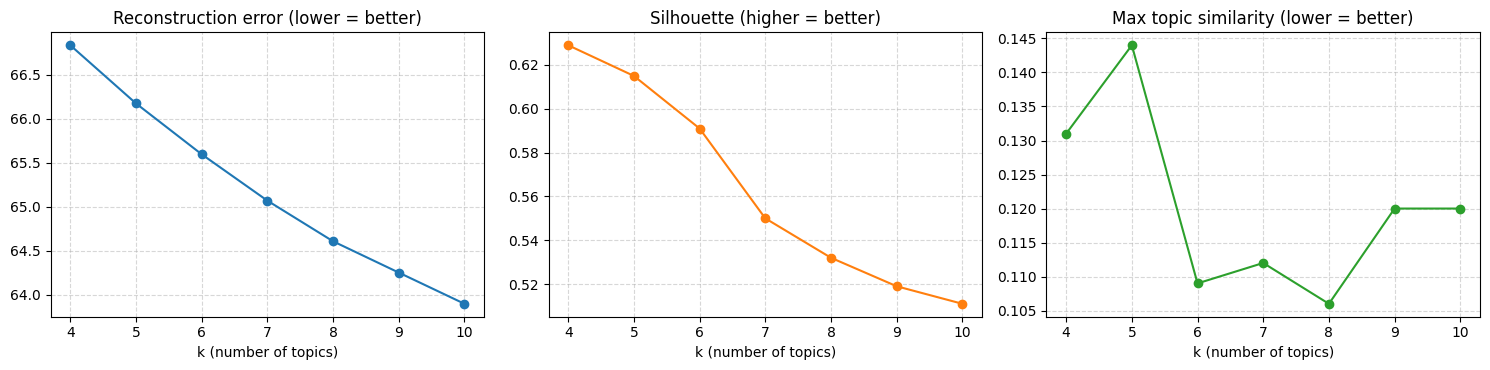


=== k=5 ===
T1: sidelink, positioning, sci, pool, feedback, reservation, link, frequency
T2: csi, report, reporting, measurement, reports, measurements, interference, domain
T3: beam, failure, beams, recovery, management, beamforming, detection, measurement
T4: harq, feedback, request, hybrid, automatic, repeat, downlink, ack
T5: random, access, uplink, cell, prach, timing, rach, bwp

=== k=6 ===
T1: sidelink, positioning, sci, pool, feedback, reservation, link, frequency
T2: csi, report, reporting, measurement, reports, measurements, interference, domain
T3: beam, failure, beams, recovery, management, beamforming, detection, measurement
T4: harq, feedback, request, hybrid, automatic, repeat, ack, downlink
T5: random, access, prach, rach, preamble, physical, response, repetition
T6: uplink, cell, grant, downlink, bwp, timing, bandwidth, scheduling

=== k=7 ===
T1: sidelink, positioning, sci, pool, feedback, reservation, link, frequency
T2: csi, report, reporting, measurement, reports,

In [36]:
from sklearn.decomposition import NMF
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

rows = []
models = {}
for k in range(4, 11):
    m = NMF(n_components=k, random_state=42, max_iter=500)
    W_k = m.fit_transform(X)
    H_k = m.components_
    models[k] = (W_k, H_k)

    # 1) 재구성 오차: 낮을수록 원래 TF-IDF를 잘 복원
    err = m.reconstruction_err_

    # 2) 실루엣: 문서를 대표 토픽으로 나눴을 때 그룹이 얼마나 뚜렷한가 (코사인 거리)
    labels = W_k.argmax(axis=1)
    sil = silhouette_score(normalize(W_k), labels, metric='euclidean', sample_size=3000, random_state=42)

    # 3) 토픽 중복도: 토픽 간 단어 벡터의 최대 코사인 유사도 (높을수록 비슷한 토픽이 중복)
    Hn = normalize(H_k)
    sim = Hn @ Hn.T
    np.fill_diagonal(sim, 0)
    max_sim = sim.max()

    # 4) 가장 작은 토픽의 문서 비중: 너무 작으면 의미 없는 토픽일 가능성
    min_share = np.bincount(labels, minlength=k).min() / len(labels) * 100

    rows.append({'k': k, '재구성오차': round(err, 3), '실루엣': round(sil, 3),
                 '토픽간최대유사도': round(max_sim, 3), '최소토픽비중(%)': round(min_share, 1)})

eval_df = pd.DataFrame(rows).set_index('k')
display(eval_df)

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(eval_df.index, eval_df['재구성오차'], 'o-')
axes[0].set_title('Reconstruction error (lower = better)')
axes[1].plot(eval_df.index, eval_df['실루엣'], 'o-', color='tab:orange')
axes[1].set_title('Silhouette (higher = better)')
axes[2].plot(eval_df.index, eval_df['토픽간최대유사도'], 'o-', color='tab:green')
axes[2].set_title('Max topic similarity (lower = better)')
for ax in axes:
    ax.set_xlabel('k (number of topics)')
    ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('nmf_k_selection.png', dpi=200)
plt.show()

# 해석 가능성 확인용: k별 토픽 상위 단어 (직접 읽고 판단)
for k in [5, 6, 7, 8]:
    print(f'\n=== k={k} ===')
    for t, w in enumerate(models[k][1]):
        print(f'T{t+1}:', ', '.join(terms[w.argsort()[::-1][:8]]))

,상위 키워드
T1,"sidelink, positioning, sci, pool, feedback, reservation, link, frequency"
T2,"csi, report, reporting, measurement, reports, measurements, interference, domain"
T3,"beam, failure, beams, recovery, management, beamforming, detection, measurement"
T4,"harq, feedback, hybrid, automatic, repeat, request, ack, downlink"
T5,"random, access, prach, rach, preamble, physical, response, repetition"
T6,"uplink, grant, downlink, scheduling, bwp, pusch, shared, bandwidth"
T7,"cell, handover, cells, source, serving, mobility, timing, layer"



[연도별 토픽 출원 건수]


topic,1,2,3,4,5,6,7
label,,,,,,,
2020,180,119,90,118,94,215,124
2021,585,165,184,185,121,354,128
2022,296,175,110,118,90,257,133
2023,170,110,68,93,51,146,98
2024,63,47,27,62,79,124,65



[연도별 토픽 비중(%)]


topic,1,2,3,4,5,6,7
label,,,,,,,
2020,19.15,12.66,9.57,12.55,10.00,22.87,13.19
2021,33.97,9.58,10.69,10.74,7.03,20.56,7.43
2022,25.11,14.84,9.33,10.01,7.63,21.80,11.28
2023,23.10,14.95,9.24,12.64,6.93,19.84,13.32
2024,13.49,10.06,5.78,13.28,16.92,26.55,13.92


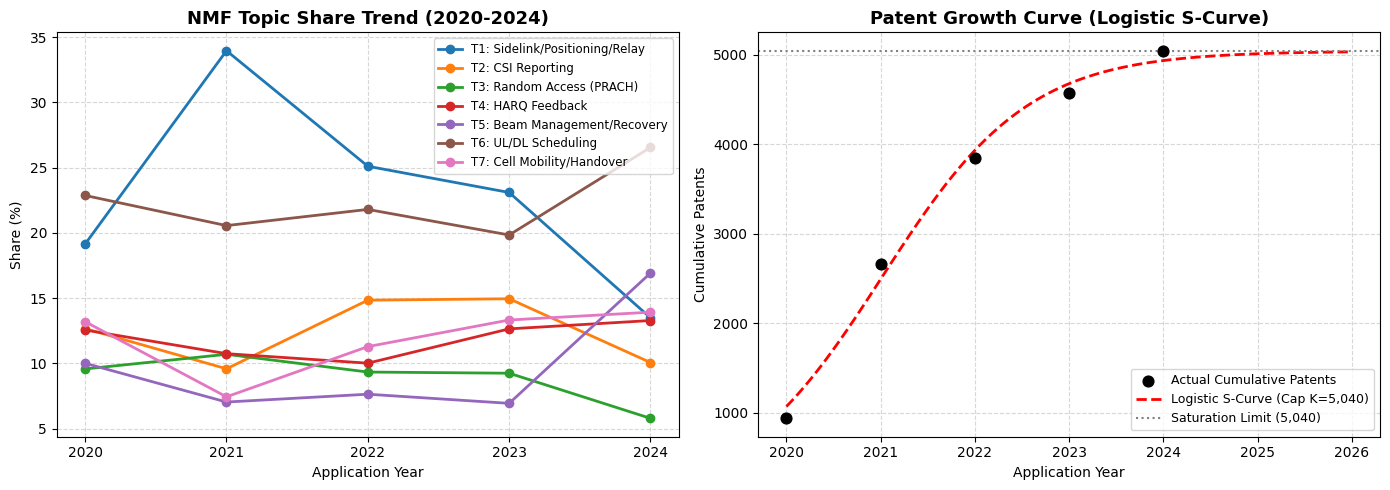

추정 포화치(K): 5,039.5건 | 성장률(r): 1.288 | 변곡점 연도: 2021.02년


In [37]:
from sklearn.decomposition import NMF
from scipy.optimize import curve_fit

# 1. NMF 토픽 모델링 (이전 셀의 X, terms 재사용)
k = 7
nmf_model = NMF(n_components=k, random_state=42, max_iter=500)
W = nmf_model.fit_transform(X)
H = nmf_model.components_

# 토픽별 상위 키워드 표 출력
nmf_topics = {}
for t, weight in enumerate(H):
    top_words = [terms[i] for i in weight.argsort()[::-1][:8]]
    nmf_topics[f'T{t+1}'] = ', '.join(top_words)
display(pd.DataFrame.from_dict(nmf_topics, orient='index', columns=['상위 키워드']))

# 문서별 대표 토픽 할당 및 연도별 건수·비중(%) 집계
patent_df['topic'] = W.argmax(axis=1) + 1
yearly_counts = pd.crosstab(patent_df['label'], patent_df['topic'])
yearly_ratio = pd.crosstab(patent_df['label'], patent_df['topic'], normalize='index').mul(100).round(2)

print("\n[연도별 토픽 출원 건수]")
display(yearly_counts)
print("\n[연도별 토픽 비중(%)]")
display(yearly_ratio)

# 2. 시각화: NMF 토픽 비중 추이 & 로지스틱 성장곡선(S-Curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# [왼쪽] 연도별 NMF 토픽 비중 변화
topic_labels = {
    1: 'T1: Sidelink/Positioning/Relay',
    2: 'T2: CSI Reporting',
    3: 'T3: Random Access (PRACH)',
    4: 'T4: HARQ Feedback',
    5: 'T5: Beam Management/Recovery',
    6: 'T6: UL/DL Scheduling',
    7: 'T7: Cell Mobility/Handover'
}
for col in yearly_ratio.columns:
    axes[0].plot(yearly_ratio.index, yearly_ratio[col], marker='o', linewidth=2, label=topic_labels[col])

axes[0].set_title('NMF Topic Share Trend (2020-2024)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Application Year')
axes[0].set_ylabel('Share (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=8.5, loc='best')

# [오른쪽] 누적 특허 건수 기반 로지스틱 성장곡선
yearly_total = patent_df['label'].astype(int).value_counts().sort_index()
cum_total = yearly_total.cumsum()

years = cum_total.index.values
t = years - years[0]
cum_counts = cum_total.values

def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

popt, _ = curve_fit(logistic, t, cum_counts, p0=[6000, 1.0, 1.0], maxfev=10000)
K_est, r_est, t0_est = popt

t_future = np.linspace(0, 6, 100)
years_future = years[0] + t_future
y_pred = logistic(t_future, *popt)

axes[1].scatter(years, cum_counts, color='black', s=60, zorder=5, label='Actual Cumulative Patents')
axes[1].plot(years_future, y_pred, 'r--', linewidth=2, label=f'Logistic S-Curve (Cap K={K_est:,.0f})')
axes[1].axhline(K_est, color='gray', linestyle=':', label=f'Saturation Limit ({K_est:,.0f})')
axes[1].set_title('Patent Growth Curve (Logistic S-Curve)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Application Year')
axes[1].set_ylabel('Cumulative Patents')
axes[1].set_xticks([2020, 2021, 2022, 2023, 2024, 2025, 2026])
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=9, loc='lower right')

plt.tight_layout()
plt.savefig('nmf_and_growth_curve.png', dpi=200)
plt.show()

print(f"추정 포화치(K): {K_est:,.1f}건 | 성장률(r): {r_est:.3f} | 변곡점 연도: {years[0] + t0_est:.2f}년")

In [47]:
new_terms = ['5g','6g','ntn','iab','ris','ai','ml','xr','iot','tci','ssb','srs','prs','sps','tdd','fdd','sci','uci','nru','lbt','rlc','pci','pmi','mbs','v2x']
vocab = {w: i for i, w in enumerate(terms)}
rows = []
for w in new_terms:
    if w not in vocab:
        rows.append({'단어': w, '결과': '1,000개 단어에 못 들어옴'})
        continue
    j = vocab[w]
    t = H[:, j].argmax()
    rank = int((H[t] > H[t, j]).sum() + 1)
    rows.append({'단어': w, '결과': f'T{t+1} {rank}위', 'DF(%)': round(X[:, j].nnz / X.shape[0] * 100, 1)})
display(pd.DataFrame(rows))

,단어,결과,DF(%)
0,5g,T7 180위,0.8
1,6g,"1,000개 단어에 못 들어옴",NaN
2,ntn,T7 65위,0.5
3,iab,T5 112위,0.3
4,ris,T3 59위,0.5
5,ai,T3 267위,0.2
6,ml,T2 91위,0.6
7,xr,T6 348위,0.3
8,iot,T6 475위,0.3
9,tci,T3 21위,1.7


In [38]:
# 토픽별 핵심 키워드 (영역명을 대표하는 단어/표현)
key_terms = {
    'sidelink': r'side-?\s?link',
    'csi': r'\bcsi\b|channel state information',
    'random access': r'random access|prach|\brach\b',
    'harq': r'\bharq\b|hybrid automatic repeat',
    'beam': r'\bbeam',
    'uplink grant/scheduling': r'uplink grant|scheduling|\bpusch\b',
    'handover/mobility': r'handover|mobility',
}

doc_lower = patent_df['document'].str.lower()
rows = {}
for name, rx in key_terms.items():
    flag = doc_lower.str.contains(rx, regex=True)
    # 각 토픽(배정된 특허) 중 이 키워드가 들어간 특허의 비율(%)
    rows[name] = (flag.groupby(patent_df['topic']).mean() * 100).round(1)

leak = pd.DataFrame(rows)            # 행: 배정된 토픽, 열: 키워드
leak.index = [f'T{i}' for i in leak.index]
print('[배정된 토픽(행)별로, 키워드(열)가 제목·요약에 들어 있는 특허 비율(%)]')
display(leak)

[배정된 토픽(행)별로, 키워드(열)가 제목·요약에 들어 있는 특허 비율(%)]


,sidelink,csi,random access,harq,beam,uplink grant/scheduling,handover/mobility
T1,99.5,1.2,0.0,0.3,4.3,8.3,0.3
T2,7.1,91.7,0.3,0.3,14.3,7.0,0.2
T3,15.9,9.0,1.3,0.4,99.2,5.6,1.0
T4,28.6,7.3,0.7,66.7,3.8,21.0,0.3
T5,12.9,3.9,65.3,1.6,14.7,9.7,5.7
T6,7.9,4.5,1.6,1.7,6.8,38.7,0.8
T7,4.6,5.1,4.0,0.9,9.7,4.2,50.4


In [39]:
import re

# 1. 사이드링크 표식: 제목+요약에 'sidelink' 또는 'side link'가 들어간 특허
pat = re.compile(r'side-?\s?link', re.IGNORECASE)
patent_df['is_sidelink'] = patent_df['document'].apply(lambda x: bool(pat.search(x)))

# 2. 연도별 사이드링크 특허 건수·비중
sl_year = patent_df.groupby('label')['is_sidelink'].agg(['sum', 'count'])
sl_year.columns = ['사이드링크 특허 수', '전체 특허 수']
sl_year['비중(%)'] = (sl_year['사이드링크 특허 수'] / sl_year['전체 특허 수'] * 100).round(1)
print('[연도별 사이드링크 언급 특허]')
display(sl_year)

# 3. 토픽별로 사이드링크 특허가 얼마나 분포하는지
sl_topic = pd.crosstab(patent_df['topic'], patent_df['is_sidelink'])
sl_topic.columns = ['비사이드링크', '사이드링크']
sl_topic['사이드링크 비율(%)'] = (sl_topic['사이드링크'] / sl_topic.sum(axis=1) * 100).round(1)
print('\n[토픽별 사이드링크 특허 분포]')
display(sl_topic)

# 4. T1 안에 있는 사이드링크 특허 vs 다른 토픽에 있는 사이드링크 특허
total_sl = patent_df['is_sidelink'].sum()
in_t1 = ((patent_df['topic'] == 1) & patent_df['is_sidelink']).sum()
print(f'\n사이드링크 언급 특허 총 {total_sl}건 중 T1에 배정된 건수: {in_t1}건 ({in_t1/total_sl*100:.1f}%)')

[연도별 사이드링크 언급 특허]


,사이드링크 특허 수,전체 특허 수,비중(%)
label,,,
2020,267,940,28.4
2021,776,1722,45.1
2022,396,1179,33.6
2023,217,736,29.5
2024,84,467,18.0



[토픽별 사이드링크 특허 분포]


,비사이드링크,사이드링크,사이드링크 비율(%)
topic,,,
1,7,1287,99.5
2,572,44,7.1
3,403,76,15.9
4,411,165,28.6
5,379,56,12.9
6,1009,87,7.9
7,523,25,4.6



사이드링크 언급 특허 총 1740건 중 T1에 배정된 건수: 1287건 (74.0%)


In [40]:
pd.set_option('display.max_colwidth', 400)

n_rep = 3  # 토픽별로 볼 대표 특허 수 (이 중 1~2건을 보고서에 사용)

# 가중치 W가 큰 문서 = 그 토픽의 단어 패턴을 가장 강하게 가진 문서
# 같은 토픽으로 배정된(argmax) 문서 중에서만 고름
rep_rows = []
for t in range(k):
    idx = np.where(patent_df['topic'].values == t + 1)[0]
    top_idx = idx[np.argsort(W[idx, t])[::-1][:n_rep]]
    for rank, i in enumerate(top_idx, 1):
        rep_rows.append({
            '토픽': f'T{t+1}',
            '순위': rank,
            '특허번호': patent_df.display_key.iloc[i],
            '출원연도': patent_df.label.iloc[i],
            '발명의명칭': patent_df.title.iloc[i],
            'W가중치': round(W[i, t], 3),
            '요약(앞부분)': patent_df.document.iloc[i][:300]
        })
rep_df = pd.DataFrame(rep_rows)
display(rep_df)

# 5.3절 표용: 토픽별 특허 수와 전체 대비 비중
topic_summary = patent_df['topic'].value_counts().sort_index().to_frame('특허 수')
topic_summary['비중(%)'] = (topic_summary['특허 수'] / len(patent_df) * 100).round(1)
topic_summary['상위 키워드'] = [nmf_topics[f'T{t}'] for t in topic_summary.index]
display(topic_summary)

rep_df.to_csv('representative_patents.csv', index=False, encoding='utf-8-sig')

,토픽,순위,특허번호,출원연도,발명의명칭,W가중치,요약(앞부분)
0,T1,1,US 2022/0070850 A1,2021,SIGNALING AN INDICATION OF A SIDELINK TRANSMISSION,0.208,"SIGNALING AN INDICATION OF A SIDELINK TRANSMISSION Various aspects of the present disclosure generally relate to wireless communication. In some aspects, a first user equipment (UE) may transmit, to a second UE, an indication of a transmission on a sidelink resource from the first UE to the second U"
1,T1,2,US 11765696 B2,2020,Sidelink resource allocation for device-to-device communications,0.201,"Sidelink resource allocation for device-to-device communications Aspects relate to wireless communication devices configured to facilitate power conservation and sidelink communications. According to one example, a wireless communication device can transmit a first sidelink transmission, determine o"
2,T1,3,US 11477764 B2,2020,Transmitting system information on sidelink,0.194,"Transmitting system information on sidelink Certain aspects of the present disclosure provide techniques for transmitting system information on sidelink. A method that may be performed by a first user equipment (UE) includes receiving first system information from a second UE; determining, based on"
3,T2,1,US 2021/0143882 A1,2020,CSI REPORT INCLUDING INFORMATION IDENTIFYING CSI-RS,0.270,"CSI REPORT INCLUDING INFORMATION IDENTIFYING CSI-RS A method, a computer-readable medium, and an apparatus for wireless communication at a first user equipment (UE). A channel state information (CSI) report trigger can be received from a second UE, and a channel state information reference signal (C"
4,T2,2,US 2021/0083740 A1,2020,CSI REPORT SETTING BY THE CSI-TRANSMITTING USER EQUIPMENT,0.262,CSI REPORT SETTING BY THE CSI-TRANSMITTING USER EQUIPMENT Some aspects provide a method for wireless communication by a first wireless device. The method generally includes transmitting control information regarding at least one of scheduling or configuration of a channel state information (CSI) rep
5,T2,3,US 2024/0322966 A1,2022,CHANNEL STATE INFORMATION (CSI) PRIORITY AND MULTIPLEXING FOR APERIODIC CSI REPORTING,0.261,"CHANNEL STATE INFORMATION (CSI) PRIORITY AND MULTIPLEXING FOR APERIODIC CSI REPORTING The present disclosure provides systems, methods and apparatus, including computer programs encoded on computer storage media, for channel state information (CSI) priority and multiplexing for aperiodic CSI reporti"
6,T3,1,US 2023/0118940 A1,2021,BEAM FAILURE DETECTION PER BEAM FOR MULTI-BEAM COMMUNICATIONS,0.233,BEAM FAILURE DETECTION PER BEAM FOR MULTI-BEAM COMMUNICATIONS Certain aspects of the present disclosure provide techniques for beam failure detection per beam. A method that may be performed by a user equipment (UE) includes communicating with a network entity via a plurality of beams associated wit
7,T3,2,US 2024/0113767 A1,2023,BEAM FAILURE RECOVERY REQUEST FOR PER BEAM GROUP BEAM FAILURE RECOVERY,0.229,"BEAM FAILURE RECOVERY REQUEST FOR PER BEAM GROUP BEAM FAILURE RECOVERY Various aspects of the present disclosure generally relate to wireless communication. In some aspects, a user equipment (UE) may detect beam failure for a first beam group in a cell including the first beam group and a second bea"
8,T3,3,US 12375151 B2,2022,Beam failure recovery via sidelink,0.226,"Beam failure recovery via sidelink Methods, systems, and devices for wireless communications are described. A first user equipment (UE) may communicate with a network node via a first wireless link using a first beam according to a first beam configuration. In some examples, the first UE may transmi"
9,T4,1,US 2023/0143786 A1,2021,HYBRID AUTOMATIC REPEAT REQUEST FEEDBACK VERIFICATION,0.339,"HYBRID AUTOMATIC REPEAT REQUEST FEEDBACK VERIFICATION Various aspects of the present disclosure generally relate to wireless communication. In some aspects, a user equipment (UE) may transmit hybrid automatic repeat request (HARQ) feedback for a downlink transmission from a base station; receive an"


,특허 수,비중(%),상위 키워드
topic,,,
1,1294,25.7,"sidelink, positioning, sci, pool, feedback, reservation, link, frequency"
2,616,12.2,"csi, report, reporting, measurement, reports, measurements, interference, domain"
3,479,9.5,"beam, failure, beams, recovery, management, beamforming, detection, measurement"
4,576,11.4,"harq, feedback, hybrid, automatic, repeat, request, ack, downlink"
5,435,8.6,"random, access, prach, rach, preamble, physical, response, repetition"
6,1096,21.7,"uplink, grant, downlink, scheduling, bwp, pusch, shared, bandwidth"
7,548,10.9,"cell, handover, cells, source, serving, mobility, timing, layer"


['H04L1/1822;;H04W76/27;;H04L1/1822;;H04L1/1819;;H04W72/0446;;H04W72/23;;H04W72/535;;H04W76/27', 'H04L5/0055;;H04L1/0011;;H04L1/0052;;H04L1/1819;;H04W84/12;;H04L1/1819;;H04L5/0055;;H04W8/245;;H04W80/02;;H04W84/12', 'H04L1/1854;;H04L1/1864;;H04W72/1263;;H04L1/1812;;H04W72/20']


,특허 수,비율(%)
H04W,4521,89.6
H04L,3237,64.2
H04B,1794,35.6
G01S,180,3.6
H04J,74,1.5
G06N,72,1.4
H01Q,32,0.6
H02J,16,0.3
G08G,13,0.3
G06F,12,0.2


,H04W,H04L,H04B,G01S,H04J,G06N
label,,,,,,
2020,92.2,71.7,41.4,1.7,2.1,0.7
2021,93.3,64.0,33.9,3.5,1.3,1.4
2022,87.6,63.4,36.0,4.3,1.6,2.0
2023,84.6,59.9,34.6,4.9,0.7,1.9
2024,83.7,58.5,30.2,3.6,1.5,0.9


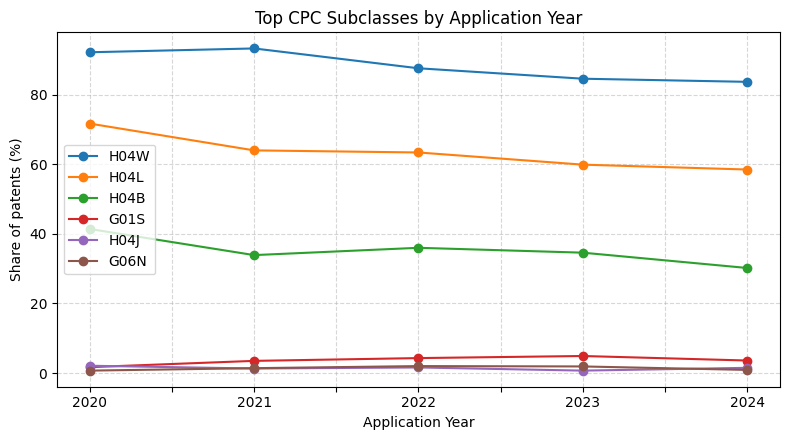

In [41]:
# 형식 확인
print(raw_df['CPC Classifications'].dropna().head(3).tolist())

# 서브클래스(앞 4글자, 예: H04W) 추출 — 한 특허에서 중복 제거
sub = raw_df['CPC Classifications'].fillna('').str.findall(r'[A-H]\d{2}[A-Z]').apply(lambda x: sorted(set(x)))
patent_df['cpc_sub'] = sub

# 3.3절용: 서브클래스별 특허 수와 비율 (분모 = 전체 특허 수, 복수 코드라 합 > 100%)
from collections import Counter
cnt = Counter(c for lst in sub for c in lst)
cpc_tbl = pd.DataFrame({'특허 수': pd.Series(cnt)}).sort_values('특허 수', ascending=False).head(10)
cpc_tbl['비율(%)'] = (cpc_tbl['특허 수'] / len(patent_df) * 100).round(1)
display(cpc_tbl)

# 4.2 그림 ②용: 연도별 상위 서브클래스 비율 (분모 = 그 해 특허 수)
top_codes = cpc_tbl.index[:6]
year_cpc = pd.DataFrame({c: patent_df.groupby('label')['cpc_sub'].apply(lambda s: s.apply(lambda l: c in l).mean() * 100)
                         for c in top_codes}).round(1)
display(year_cpc)

ax = year_cpc.plot(marker='o', figsize=(8, 4.5))
ax.set_ylabel('Share of patents (%)'); ax.set_xlabel('Application Year')
ax.set_title('Top CPC Subclasses by Application Year')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.savefig('cpc_by_year.png', dpi=200); plt.show()

,특허 수,비율(%)
H04W72,3030,60.1
H04L5,2474,49.0
H04B7,1590,31.5
H04L1,1356,26.9
H04W76,1172,23.2
H04W24,956,19.0
H04W92,922,18.3
H04W74,770,15.3
H04W52,544,10.8
H04W56,461,9.1


,H04W72,H04L5,H04B7,H04L1,H04W76,H04W24,H04W92,H04W74
label,,,,,,,,
2020,65.5,56.5,37.1,33.6,31.5,22.1,17.9,17.0
2021,68.1,49.0,30.1,29.3,27.8,20.1,23.6,14.6
2022,55.0,49.3,32.4,22.9,17.0,19.0,16.8,14.4
2023,52.4,44.6,30.0,21.6,17.8,17.3,13.6,12.9
2024,44.1,40.7,25.7,22.9,14.1,10.9,10.5,20.1


,H04W72,H04L5,H04B7,H04L1,H04W76,H04W24,H04W92,H04W74
2020→2024 차이(%p),-21.4,-15.8,-11.4,-10.7,-17.4,-11.2,-7.4,3.1


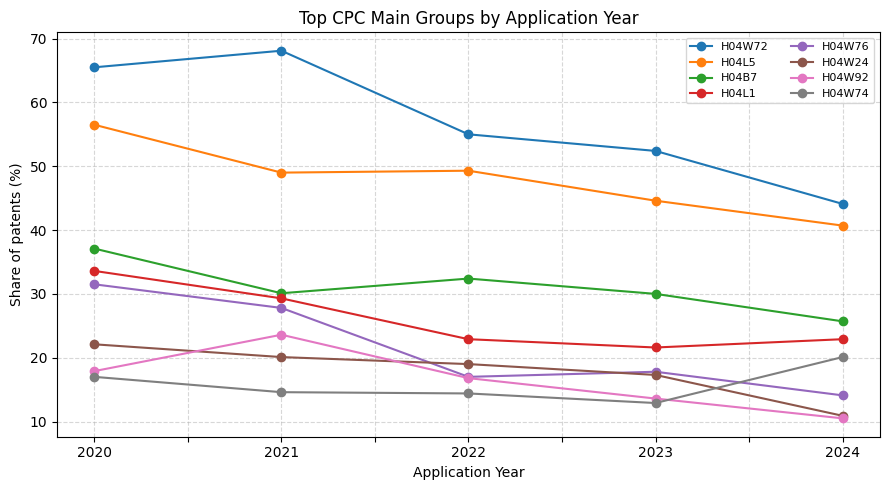

In [42]:
# 메인 그룹(예: H04W72) 추출 — 한 특허에서 중복 제거
grp = raw_df['CPC Classifications'].fillna('').str.findall(r'([A-H]\d{2}[A-Z])\s?(\d+)/').apply(
    lambda lst: sorted(set(a + b for a, b in lst)))
patent_df['cpc_grp'] = grp

cnt_g = Counter(c for lst in grp for c in lst)
grp_tbl = pd.DataFrame({'특허 수': pd.Series(cnt_g)}).sort_values('특허 수', ascending=False).head(15)
grp_tbl['비율(%)'] = (grp_tbl['특허 수'] / len(patent_df) * 100).round(1)
display(grp_tbl)

# 연도별 비율 (분모 = 그 해 특허 수)
top_g = grp_tbl.index[:8]
year_grp = pd.DataFrame({c: patent_df.groupby('label')['cpc_grp'].apply(lambda s: s.apply(lambda l: c in l).mean() * 100)
                         for c in top_g}).round(1)
display(year_grp)
display((year_grp.loc['2024'] - year_grp.loc['2020']).round(1).rename('2020→2024 차이(%p)').to_frame().T)

ax = year_grp.plot(marker='o', figsize=(9, 5))
ax.set_ylabel('Share of patents (%)'); ax.set_xlabel('Application Year')
ax.set_title('Top CPC Main Groups by Application Year')
ax.grid(True, linestyle='--', alpha=0.5); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig('cpc_group_by_year.png', dpi=200); plt.show()

In [43]:
# 1) 연도별 특허당 CPC 그룹 수, 등록본(B)/공개본(A) 비율
patent_df['n_grp'] = patent_df['cpc_grp'].str.len()
patent_df['kind'] = raw_df['Kind']
print('[연도별 특허당 평균 CPC 그룹 수]')
print(patent_df.groupby('label')['n_grp'].mean().round(2))
print('\n[연도별 문서 종류 비율(%)]')
print(pd.crosstab(patent_df['label'], patent_df['kind'], normalize='index').mul(100).round(1))
print('\n[연도×종류별 평균 CPC 그룹 수]')
print(patent_df.groupby(['label', 'kind'])['n_grp'].mean().unstack().round(2))

# 2) 토픽별로 주요 그룹을 가진 특허 비율 (NMF와 CPC 교차검증)
chk_groups = ['H04W72', 'H04W74', 'H04W92', 'H04L1', 'H04B7', 'H04W36']
for c in chk_groups:
    patent_df[c] = patent_df['cpc_grp'].apply(lambda l: c in l)
print('\n[토픽별로 해당 CPC 그룹을 가진 특허 비율(%)]')
display((patent_df.groupby('topic')[chk_groups].mean() * 100).round(1))

[연도별 특허당 평균 CPC 그룹 수]
label
2020    4.36
2021    3.95
2022    3.50
2023    3.30
2024    2.95
Name: n_grp, dtype: float64

[연도별 문서 종류 비율(%)]
kind     A1   A9   B1    B2
label                      
2020   51.2  0.1  0.9  47.9
2021   56.8  0.0  1.2  42.0
2022   68.9  0.3  1.0  29.8
2023   72.7  0.0  0.1  27.2
2024   90.1  0.0  0.6   9.2

[연도×종류별 평균 CPC 그룹 수]
kind     A1    A9    B1    B2
label                        
2020   4.29  8.00  4.50  4.44
2021   3.87   NaN  4.00  4.07
2022   3.54  2.75  3.17  3.41
2023   3.33   NaN  3.00  3.22
2024   2.93   NaN  3.33  3.12

[토픽별로 해당 CPC 그룹을 가진 특허 비율(%)]


,H04W72,H04W74,H04W92,H04L1,H04B7,H04W36
topic,,,,,,
1,76.5,15.5,51.5,20.3,11.1,1.1
2,41.4,1.6,5.5,27.3,75.6,1.5
3,45.9,9.8,9.2,7.3,91.4,5.6
4,65.3,6.6,11.6,87.3,17.4,0.7
5,47.1,74.3,9.9,17.7,19.3,8.3
6,76.6,8.8,3.6,24.4,23.2,2.9
7,26.5,10.0,4.9,7.8,19.0,57.1


In [44]:
kind_grp = raw_df['Kind'].str[0].map({'A': 'A_공개본', 'B': 'B_등록본'})
yr = pd.crosstab(patent_df['label'], kind_grp)
yr['합계'] = yr.sum(axis=1)
display(yr)

total = yr['합계']
print(pd.DataFrame({'건수': total, '전년 대비(건)': total.diff()}))
print('최고 연도:', total.idxmax(), total.max())
print('2024/최고연도:', round(total['2024'] / total.max() * 100), '%')
print('2024/2020:', round(total['2024'] / total['2020'] * 100), '%')

Kind,A_공개본,B_등록본,합계
label,,,
2020,482,458,940
2021,978,744,1722
2022,816,363,1179
2023,535,201,736
2024,421,46,467


         건수  전년 대비(건)
label                
2020    940       NaN
2021   1722     782.0
2022   1179    -543.0
2023    736    -443.0
2024    467    -269.0
최고 연도: 2021 1722
2024/최고연도: 27 %
2024/2020: 50 %


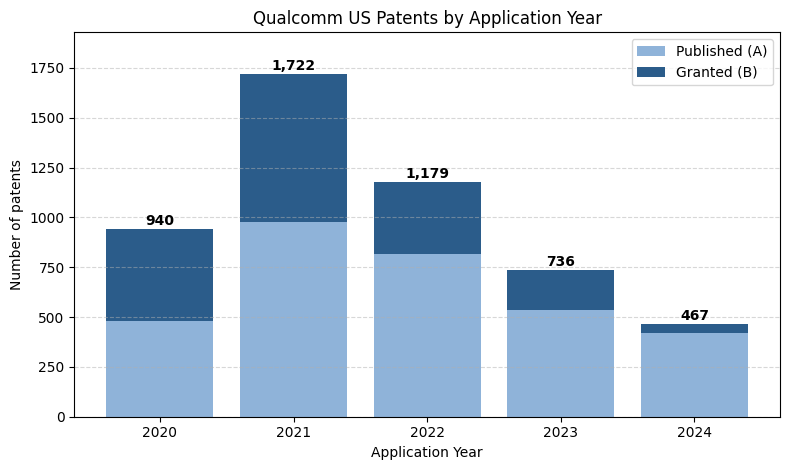

In [45]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(yr.index, yr['A_공개본'], label='Published (A)', color='#8fb3d9')
ax.bar(yr.index, yr['B_등록본'], bottom=yr['A_공개본'], label='Granted (B)', color='#2b5c8a')

for x, v in zip(yr.index, total):
    ax.text(x, v + 20, f'{v:,}', ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Application Year')
ax.set_ylabel('Number of patents')
ax.set_title('Qualcomm US Patents by Application Year')
ax.set_ylim(0, total.max() * 1.12)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig('yearly_counts.png', dpi=200)
plt.show()

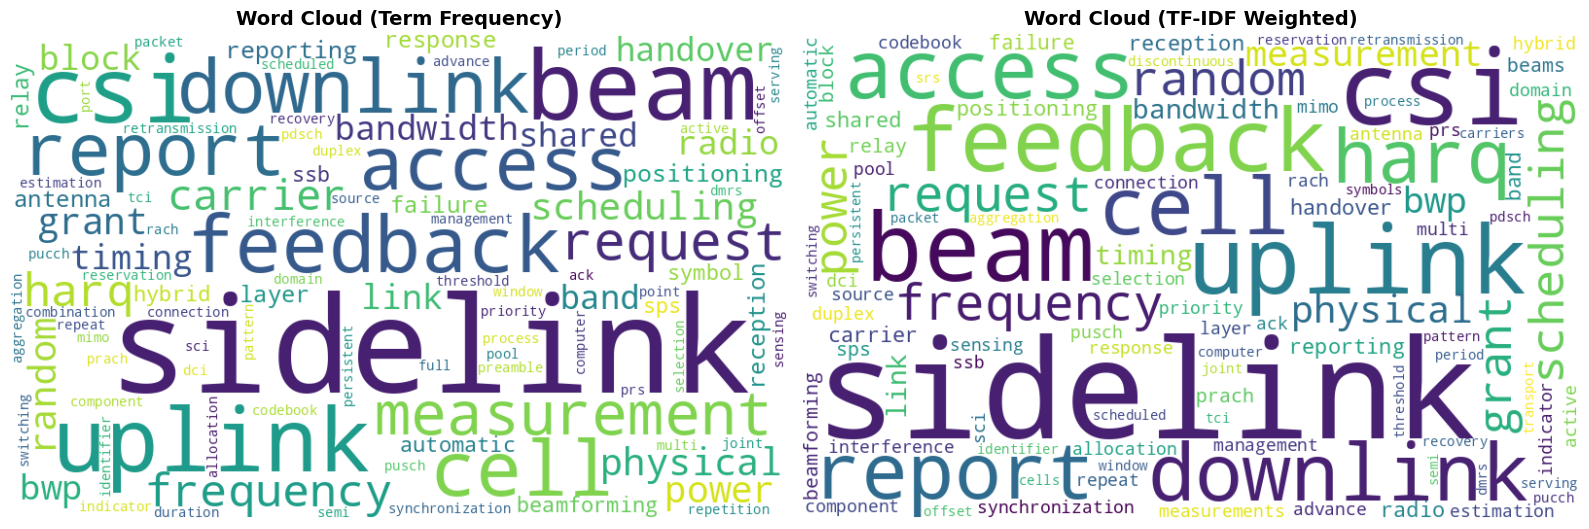

In [46]:
from wordcloud import WordCloud

# 1. [왼쪽] 전체 전처리 텍스트 빈도 기반 워드클라우드
all_text = ' '.join(patent_df['clean_doc'])
wc_freq = WordCloud(
    width=800,
    height=500,
    background_color='white',
    max_words=100,
    collocations=False,
    random_state=42
).generate(all_text)

# 2. [오른쪽] TF-IDF 가중치 기반 워드클라우드 (이전 셀의 X, terms 재사용)
tfidf_scores = dict(zip(terms, np.asarray(X.sum(axis=0)).ravel()))
wc_tfidf = WordCloud(
    width=800,
    height=500,
    background_color='white',
    max_words=100,
    random_state=42
).generate_from_frequencies(tfidf_scores)

# 3. 시각화 및 저장
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_freq, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Word Cloud (Term Frequency)', fontsize=14, fontweight='bold')

axes[1].imshow(wc_tfidf, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Word Cloud (TF-IDF Weighted)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('qualcomm_wordcloud.png', dpi=200)
plt.show()